#### 08 · Validación del emulador (PVAR → XGBoost → ruido TAR)
Compara la Hs horaria observada (1985–2025) con las simulaciones del 07 para el generador `GEN` (por defecto `h1bb24`).

- Cada simulación (1941–2022) se parte en **bloques de la misma longitud que la observación** (41 años → 2 bloques por simulación). Las bandas son p5–p95 entre bloques: así la variabilidad muestral es comparable a la de un registro de 41 años.
- Secciones: 1. régimen medio · 2. persistencia y autocorrelación · 3. estacionalidad (y ciclo diario) · 4. variabilidad interanual · 5. extremos · 6. resumen · 5B. forma de los temporales, con la comparación frente al hindcast (f histórica + ruido, 05).
- Los estadísticos se guardan en `outputs/emulador/validacion_{GEN}.pkl` para no recalcular.

In [23]:
import glob, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.signal import find_peaks

In [24]:
#### Configuración
point = "p102"
GEN = "h1bb24"
carpeta = f"outputs/emulador/{GEN}"
fichero_val = f"outputs/emulador/validacion_{GEN}.pkl"

os.makedirs("figuras", exist_ok=True)

obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"].dropna()
N_ANOS = obs.index.year.nunique()                   # longitud de cada bloque simulado
ficheros = sorted(glob.glob(f"{carpeta}/sim_*.parquet"))

U90, U99 = obs.quantile(0.90), obs.quantile(0.99)   # umbrales fijos (observados) para duraciones y temporales
U95 = obs.quantile(0.95)                            # umbral de los temporales de la sección 5B
Q_FINO = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), 1 - np.logspace(-2, -4.5, 26)]))
Q_TABLA = [0.5, 0.9, 0.99, 0.999]
LAGS = np.arange(0, 241)                            # hasta 10 días
T_RET = [2, 10, 50, 100]
print(f"obs: {N_ANOS} años | {len(ficheros)} simulaciones | U90 = {U90:.2f} m, U99 = {U99:.2f} m")

obs: 41 años | 100 simulaciones | U90 = 1.91 m, U99 = 3.73 m


In [25]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def banda(ax, x, arr, color=AZUL, label="sim. p5–p95", mediana=True):
    """Banda p5–p95 (y mediana) entre bloques simulados; arr con forma (bloque, x)."""
    p5, p50, p95 = np.nanpercentile(arr, [5, 50, 95], axis=0)
    ax.fill_between(x, p5, p95, color=color, alpha=0.25, lw=0, label=label)
    if mediana:
        ax.plot(x, p50, color=color, lw=1.5, label="sim. mediana")

#### Estadísticos de un bloque (se aplica igual a la observación y a cada bloque simulado)

In [26]:
#### Funciones de temporales (5B): se definen aquí porque estadisticos() las usa
SEP_H = 48                                   # dos excedencias separadas más de 48 h son temporales distintos

def eventos(s, u, sep=SEP_H):
    """Temporales por excedencia de u, agrupados por rachas: duración, pico, energía, subida y bajada."""
    v = s.asfreq("h").values
    exc = np.flatnonzero(v > u)
    if len(exc) < 2:
        return pd.DataFrame(columns=["inicio", "dur", "pico", "energia", "subida", "bajada"])
    grupo = np.r_[0, np.cumsum(np.diff(exc) > sep)]
    filas = []
    for g in np.unique(grupo):
        i = exc[grupo == g]
        tramo = v[i[0]:i[-1] + 1]
        k = np.nanargmax(tramo)
        filas.append({"inicio": i[0], "dur": len(i), "pico": tramo[k],
                      "energia": np.nansum(v[i] ** 2), "subida": k, "bajada": len(tramo) - 1 - k})
    return pd.DataFrame(filas)

def theta_intervalos(s, u):
    """Índice extremal: estimador de intervalos de Ferro y Segers (2003)."""
    T = np.diff(np.flatnonzero(s.asfreq("h").values > u)).astype(float)
    if len(T) < 2:
        return np.nan
    N = len(T) + 1
    if T.max() <= 2:
        return min(1.0, 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum()))
    return min(1.0, 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum()))

In [27]:
def acf(s, lags):
    """Autocorrelación de la serie horaria (con huecos como NaN)."""
    x = s.asfreq("h").values.astype("float64")
    x = x - np.nanmean(x)
    v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

def duraciones(s, u):
    """Duración (h) de cada racha continua por encima de u."""
    sobre = np.concatenate([[0], (s.asfreq("h").values > u).astype(int), [0]])
    d = np.diff(sobre)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def gev_niveles(am):
    c, loc, sc = genextreme.fit(am)
    return {"xi": -c, **{f"Hs{T}": genextreme.isf(1 / T, c, loc, sc) for T in T_RET}}

def estadisticos(s):
    """s: Hs horaria de un bloque de N_ANOS años completos."""
    anual = s.groupby(s.index.year)
    am = anual.max().values
    picos, _ = find_peaks(s.values, height=U99, distance=72)
    media_anual = anual.mean().values
    return {
        "q": s.quantile(Q_FINO).values,
        "media": s.mean(), "std": s.std(),
        "acf": acf(s, LAGS),
        "dur90": duraciones(s, U90),
        "mes_media": s.groupby(s.index.month).mean().values,
        "mes_q90": s.groupby(s.index.month).quantile(0.90).values,
        "mes_q99": s.groupby(s.index.month).quantile(0.99).values,
        "mes_max": s.groupby([s.index.year, s.index.month]).max().groupby(level=1).mean().values,
        "hora_media": s.groupby(s.index.hour).mean().values,
        "anual_media": media_anual, "anual_q95": anual.quantile(0.95).values,
        "std_anual_media": media_anual.std(), "std_anual_q95": anual.quantile(0.95).std(),
        "ac1_anual_media": np.corrcoef(media_anual[:-1], media_anual[1:])[0, 1],
        "am": np.sort(am),
        "temporales_10a": len(picos) * 10 / s.index.year.nunique(),
        "picos": s.values[picos],
        **gev_niveles(am),
        **{f"theta_q{q}": theta_intervalos(s, uq) for q, uq in [(95, U95), (99, U99)]},
        "ev95": eventos(s, U95), "ev99": eventos(s, U99),
        "n_ev95_ano": eventos(s, U95).assign(ano=lambda d: s.index[d["inicio"].astype(int)].year)
                        .groupby("ano").size().reindex(np.unique(s.index.year), fill_value=0).values,
    }

In [28]:
#### Observación y bloques simulados (se guarda para no recalcular)
est_obs = estadisticos(obs)

if os.path.exists(fichero_val):
    est_sim = pickle.load(open(fichero_val, "rb"))["sim"]
    print(f"cargados {len(est_sim)} bloques de {fichero_val}")
else:
    est_sim = []
    for i, fic in enumerate(ficheros):
        t = time.time()
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"].astype("float64")
        anos = np.unique(hs.index.year)
        anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]           # solo años completos
        for b in range(len(anos) // N_ANOS):
            bloque = anos[b * N_ANOS:(b + 1) * N_ANOS]
            est_sim.append(estadisticos(hs[hs.index.year.isin(bloque)]))
        print(f"sim {i:03d}: {len(anos) // N_ANOS} bloques ({time.time() - t:.0f} s)", flush=True)
    pickle.dump({"obs": est_obs, "sim": est_sim}, open(fichero_val, "wb"))

pila = lambda k: np.array([e[k] for e in est_sim])                     # (bloque, ...)
print(f"{len(est_sim)} bloques de {N_ANOS} años")

cargados 200 bloques de outputs/emulador/validacion_h1bb24.pkl
200 bloques de 41 años


In [29]:
#### Rango percentil de la observación dentro de los bloques simulados (≈ 50 ideal; < 5 o > 95 = fuera de banda)
def rango(k, v_obs=None):
    v_obs = est_obs[k] if v_obs is None else v_obs
    return 100 * np.mean(pila(k) < v_obs)

def fila(nombre, k):
    s = pila(k); p5, p50, p95 = np.percentile(s, [5, 50, 95])
    o = est_obs[k]
    return {"métrica": nombre, "obs": o, "sim p50": p50, "sim p5": p5, "sim p95": p95,
            "sesgo %": 100 * (p50 - o) / o if o else np.nan, "en banda": p5 <= o <= p95}

#### 1. Régimen medio: distribución de la Hs horaria

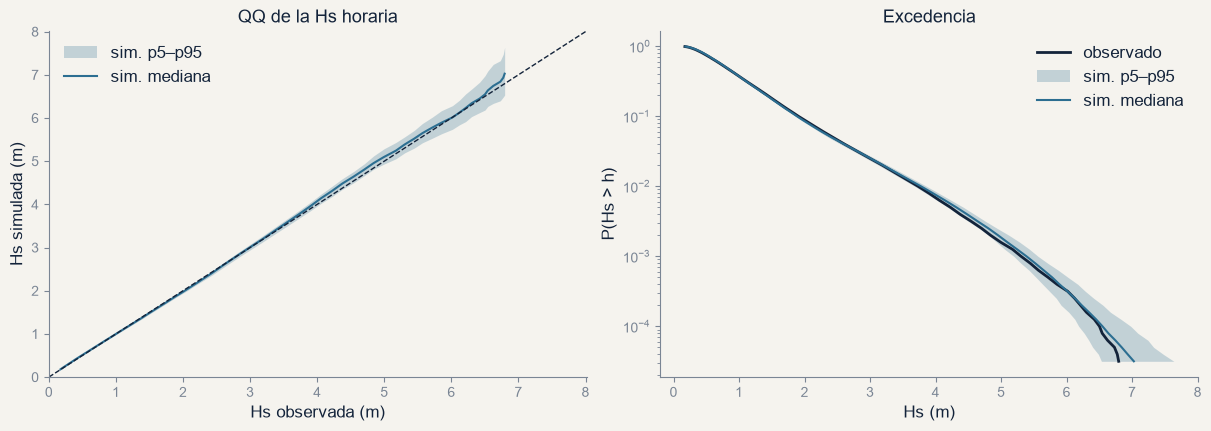

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
media,0.998,1.001,0.984,1.015,0.297,True
std,0.731,0.728,0.713,0.743,-0.388,True
q50,0.796,0.801,0.788,0.814,0.623,True
q90,1.905,1.884,1.856,1.916,-1.089,True
q99,3.731,3.775,3.680,3.860,1.181,True
q99.9,5.304,5.386,5.192,5.562,1.558,True


In [30]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### QQ: cuantiles simulados frente a observados
qs = pila("q")
p5, p50, p95 = np.percentile(qs, [5, 50, 95], axis=0)
axs[0].fill_between(est_obs["q"], p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[0].plot(est_obs["q"], p50, color=AZUL, lw=1.5, label="sim. mediana")
lim = [0, max(est_obs["q"].max(), p95.max()) * 1.05]
axs[0].plot(lim, lim, color=TINTA, lw=1, ls="--")
axs[0].set(xlabel="Hs observada (m)", ylabel="Hs simulada (m)", title="QQ de la Hs horaria", xlim=lim, ylim=lim)
axs[0].legend(frameon=False, loc="upper left")

#### Probabilidad de excedencia (cola en escala log)
axs[1].semilogy(est_obs["q"], 1 - Q_FINO, color=TINTA, lw=2, label="observado")
axs[1].fill_betweenx(1 - Q_FINO, p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[1].semilogy(p50, 1 - Q_FINO, color=AZUL, lw=1.5, label="sim. mediana")
axs[1].set(xlabel="Hs (m)", ylabel="P(Hs > h)", title="Excedencia")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_regimen_medio_{GEN}.png", dpi=200)
plt.show()

#### Tabla
filas = [fila("media", "media"), fila("std", "std")]
for j, q in enumerate(Q_TABLA):
    k = np.argmin(np.abs(Q_FINO - q))
    o = est_obs["q"][k]; s = qs[:, k]; a, m, b = np.percentile(s, [5, 50, 95])
    filas.append({"métrica": f"q{q * 100:g}", "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                  "sesgo %": 100 * (m - o) / o, "en banda": a <= o <= b})
tabla_regimen = pd.DataFrame(filas).set_index("métrica")
tabla_regimen.round(3)

#### 2. Persistencia: autocorrelación y duración de los temporales

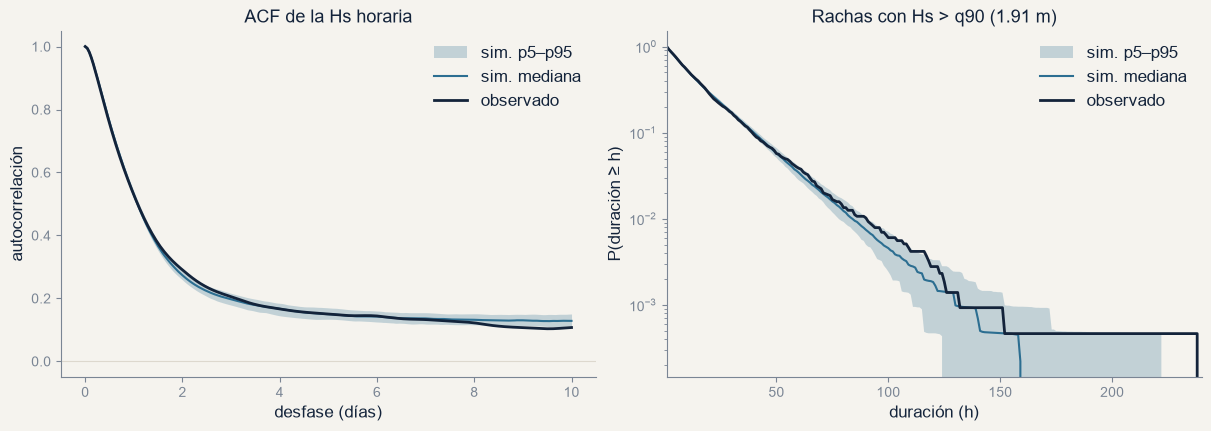

,obs,sim p50,sim p5,sim p95,en banda
métrica,,,,,
ACF 1 día,0.529,0.529,0.517,0.541,True
ACF 3 días,0.205,0.197,0.179,0.216,True
duración media > q90 (h),16.715,16.575,16.014,17.058,True


In [31]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### ACF horaria hasta 10 días
dias = LAGS / 24
banda(axs[0], dias, pila("acf"))
axs[0].plot(dias, est_obs["acf"], color=TINTA, lw=2, label="observado")
axs[0].axhline(0, color="#DDD8CE", lw=0.8)
axs[0].set(xlabel="desfase (días)", ylabel="autocorrelación", title="ACF de la Hs horaria")
axs[0].legend(frameon=False)

#### Duración de las rachas por encima de q90: función de supervivencia
d_max = 240
x = np.arange(1, d_max + 1)
superv = lambda d: np.array([(d >= h).mean() for h in x])
banda(axs[1], x, np.array([superv(e["dur90"]) for e in est_sim]))
axs[1].semilogy(x, superv(est_obs["dur90"]), color=TINTA, lw=2, label="observado")
axs[1].set(xlabel="duración (h)", ylabel="P(duración ≥ h)", title=f"Rachas con Hs > q90 ({U90:.2f} m)", xlim=(1, d_max))
axs[1].set_yscale("log")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/val_persistencia_{GEN}.png", dpi=200)
plt.show()

#### Resumen numérico
dur_med = np.array([e["dur90"].mean() for e in est_sim])
acf24, acf72 = pila("acf")[:, 24], pila("acf")[:, 72]
tabla_persist = pd.DataFrame([
    {"métrica": "ACF 1 día", "obs": est_obs["acf"][24], "sim p50": np.median(acf24), "sim p5": np.percentile(acf24, 5), "sim p95": np.percentile(acf24, 95)},
    {"métrica": "ACF 3 días", "obs": est_obs["acf"][72], "sim p50": np.median(acf72), "sim p5": np.percentile(acf72, 5), "sim p95": np.percentile(acf72, 95)},
    {"métrica": "duración media > q90 (h)", "obs": est_obs["dur90"].mean(), "sim p50": np.median(dur_med), "sim p5": np.percentile(dur_med, 5), "sim p95": np.percentile(dur_med, 95)},
]).set_index("métrica")
tabla_persist["en banda"] = (tabla_persist["sim p5"] <= tabla_persist["obs"]) & (tabla_persist["obs"] <= tabla_persist["sim p95"])
tabla_persist.round(3)

#### 3. Estacionalidad (y ciclo diario, que el PVAR a 6 h no tiene)

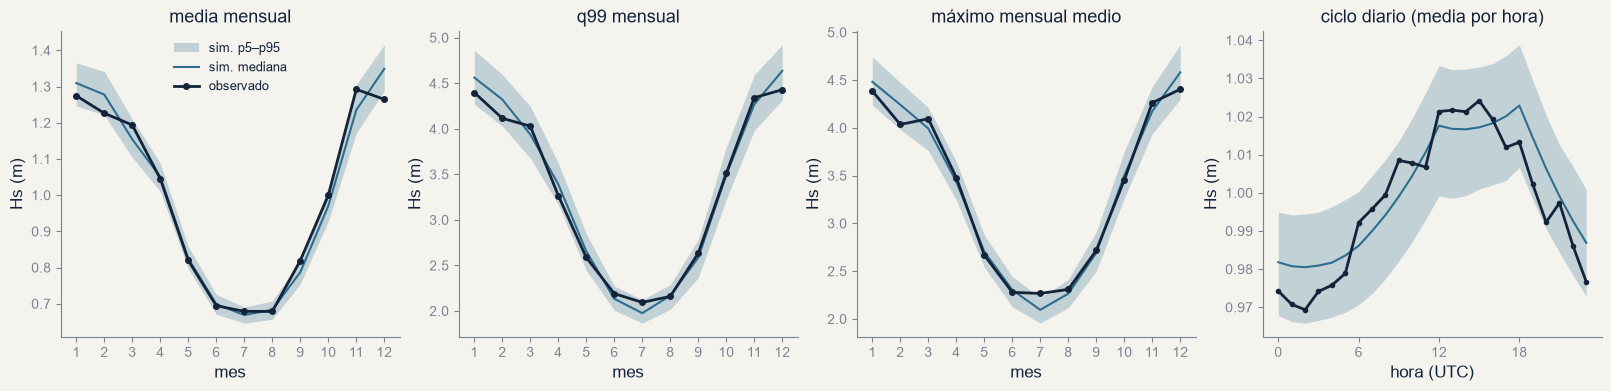

,1,2,3,4,5,6,7,8,9,10,11,12
mes_media,2.8,4.2,-3.3,0.5,0.6,0.6,-1.5,0.7,-3.9,-2.9,-4.4,6.7
mes_q90,-1.5,-0.0,-6.2,-0.8,-0.6,0.8,-2.9,-2.0,-3.7,-3.3,-3.8,5.7
mes_q99,3.7,5.0,-2.3,3.8,2.6,-2.6,-5.6,0.4,-1.8,-0.5,-1.7,4.7
mes_max,2.2,5.1,-2.5,-1.2,1.3,1.1,-7.6,-1.9,-1.0,1.4,-2.1,4.0


In [32]:
meses = np.arange(1, 13)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, k, tit in zip(axs[:3], ["mes_media", "mes_q99", "mes_max"],
                      ["media mensual", "q99 mensual", "máximo mensual medio"]):
    banda(ax, meses, pila(k))
    ax.plot(meses, est_obs[k], "o-", color=TINTA, lw=2, ms=4, label="observado")
    ax.set(title=tit, xlabel="mes", ylabel="Hs (m)", xticks=meses)
axs[0].legend(frameon=False, fontsize=9)

horas = np.arange(24)
banda(axs[3], horas, pila("hora_media"))
axs[3].plot(horas, est_obs["hora_media"], "o-", color=TINTA, lw=2, ms=3)
axs[3].set(title="ciclo diario (media por hora)", xlabel="hora (UTC)", ylabel="Hs (m)", xticks=[0, 6, 12, 18])
fig.savefig(f"figuras/val_estacionalidad_{GEN}.png", dpi=200)
plt.show()

#### Sesgo por mes (mediana simulada − observado), en %
pd.DataFrame({k: 100 * (np.median(pila(k), 0) - est_obs[k]) / est_obs[k] for k in ["mes_media", "mes_q90", "mes_q99", "mes_max"]},
             index=meses).round(1).T

#### 4. Variabilidad interanual
Si el emulador solo tuviera variabilidad de alta frecuencia, la dispersión entre años de la media o del q95 anual quedaría por debajo de la observada.

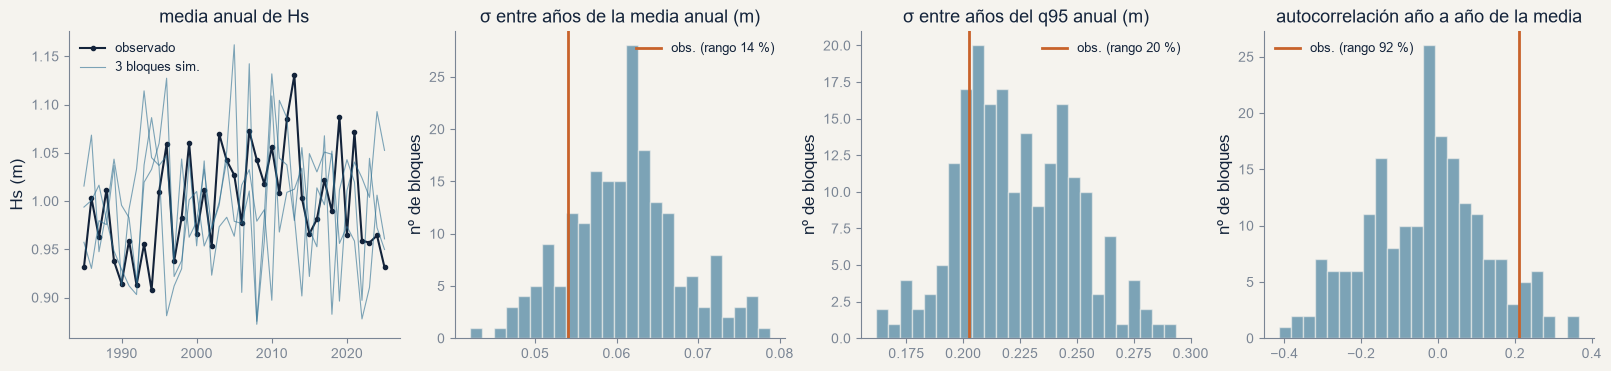

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
σ entre años de la media anual (m),0.054,0.061,0.050,0.073,13.256,True
σ entre años del q95 anual (m),0.203,0.220,0.188,0.266,8.822,True
autocorrelación año a año de la media,0.210,-0.021,-0.295,0.242,-109.836,True


In [33]:
claves = [("std_anual_media", "σ entre años de la media anual (m)"),
          ("std_anual_q95", "σ entre años del q95 anual (m)"),
          ("ac1_anual_media", "autocorrelación año a año de la media")]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)

#### Serie observada de medias anuales frente a la banda de un bloque simulado cualquiera
anos_obs = np.unique(obs.index.year)
axs[0].plot(anos_obs, est_obs["anual_media"], "o-", color=TINTA, lw=1.5, ms=3, label="observado")
for j in range(3):
    axs[0].plot(anos_obs, est_sim[j]["anual_media"], color=AZUL, lw=0.8, alpha=0.6, label="3 bloques sim." if j == 0 else None)
axs[0].set(title="media anual de Hs", ylabel="Hs (m)")
axs[0].legend(frameon=False, fontsize=9)

for ax, (k, tit) in zip(axs[1:], claves):
    v = pila(k)
    ax.hist(v, bins=25, color=AZUL, alpha=0.6, edgecolor=FONDO)
    ax.axvline(est_obs[k], color=NARANJA, lw=2, label=f"obs. (rango {rango(k):.0f} %)")
    ax.set(title=tit, ylabel="nº de bloques")
    ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/val_interanual_{GEN}.png", dpi=200)
plt.show()

tabla_interanual = pd.DataFrame([fila(t, k) for k, t in claves]).set_index("métrica")
tabla_interanual.round(3)

#### 5. Extremos: máximos anuales, niveles de retorno y temporales

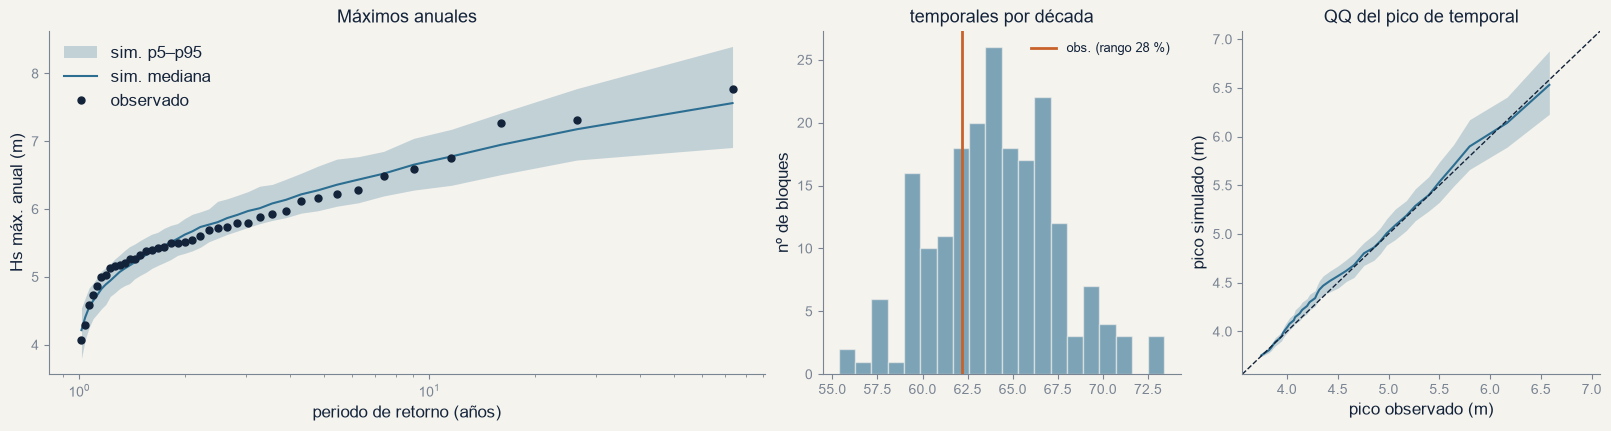

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
xi,-0.132,-0.181,-0.393,0.041,37.235,True
Hs2,5.589,5.618,5.393,5.827,0.513,True
Hs10,6.674,6.674,6.386,6.971,0.009,True
Hs50,7.426,7.391,6.848,8.073,-0.469,True
Hs100,7.698,7.645,6.953,8.505,-0.689,True
temporales / 10 años,62.195,63.902,59.012,69.768,2.745,True


In [34]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [2, 1, 1]})

#### Periodo de retorno empírico (Gringorten); misma N en obs. y bloques → misma posición
n = N_ANOS
T_emp = (n + 0.12) / (np.arange(1, n + 1) - 0.44)[::-1]
banda(axs[0], T_emp, pila("am"))
axs[0].plot(T_emp, est_obs["am"], "o", color=TINTA, ms=5, label="observado")
axs[0].set_xscale("log")
axs[0].set(xlabel="periodo de retorno (años)", ylabel="Hs máx. anual (m)", title="Máximos anuales")
axs[0].legend(frameon=False)

#### Temporales por década (picos > q99 separados 72 h)
v = pila("temporales_10a")
axs[1].hist(v, bins=20, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[1].axvline(est_obs["temporales_10a"], color=NARANJA, lw=2, label=f"obs. (rango {rango('temporales_10a'):.0f} %)")
axs[1].set(title="temporales por década", ylabel="nº de bloques")
axs[1].legend(frameon=False, fontsize=9)

#### Distribución del pico de los temporales (QQ)
qq = np.linspace(0.02, 0.98, 40)
pk_o = np.quantile(est_obs["picos"], qq)
pk_s = np.array([np.quantile(e["picos"], qq) for e in est_sim])
p5, p50, p95 = np.percentile(pk_s, [5, 50, 95], axis=0)
axs[2].fill_between(pk_o, p5, p95, color=AZUL, alpha=0.25, lw=0)
axs[2].plot(pk_o, p50, color=AZUL, lw=1.5)
lim = [pk_o.min() * 0.95, max(pk_o.max(), p95.max()) * 1.03]
axs[2].plot(lim, lim, color=TINTA, ls="--", lw=1)
axs[2].set(xlabel="pico observado (m)", ylabel="pico simulado (m)", title="QQ del pico de temporal", xlim=lim, ylim=lim)
fig.savefig(f"figuras/val_extremos_{GEN}.png", dpi=200)
plt.show()

#### GEV por bloque de 41 años
tabla_extremos = pd.DataFrame([fila(k, k) for k in ["xi"] + [f"Hs{T}" for T in T_RET]] +
                              [fila("temporales / 10 años", "temporales_10a")]).set_index("métrica")
tabla_extremos.round(3)

#### 6. Resumen

In [35]:
resumen = pd.concat({"régimen medio": tabla_regimen, "persistencia": tabla_persist,
                     "interanual": tabla_interanual, "extremos": tabla_extremos})
print(f"{resumen['en banda'].sum()} de {len(resumen)} métricas dentro de la banda p5–p95")
resumen.round(3)

18 de 18 métricas dentro de la banda p5–p95


obs  sim p50  sim p5  \
              métrica                                                          
régimen medio media                                   0.998    1.001   0.984   
              std                                     0.731    0.728   0.713   
              q50                                     0.796    0.801   0.788   
              q90                                     1.905    1.884   1.856   
              q99                                     3.731    3.775   3.680   
              q99.9                                   5.304    5.386   5.192   
persistencia  ACF 1 día                               0.529    0.529   0.517   
              ACF 3 días                              0.205    0.197   0.179   
              duración media > q90 (h)               16.715   16.575  16.014   
interanual    σ entre años de la media anual (m)      0.054    0.061   0.050   
              σ entre años del q95 anual (m)          0.203    0.220   0.188   
              autocorrelación año a año de la media   0.210   -0.021  -0.295   
extremos      xi                                     -0.132   -0.181  -0.393   
              Hs2                                     5.589    5.618   5.393   
              Hs10                                    6.674    6.674   6.386   
              Hs50                                    7.426    7.391   6.848   
              Hs100                                   7.698    7.645   6.953   
              temporales / 10 años                   62.195   63.902  59.012   

                                                     sim p95  sesgo %  \
              métrica                                                   
régimen medio media                                    1.015    0.297   
              std                                      0.743   -0.388   
              q50                                      0.814    0.623   
              q90                                      1.916   -1.089   
              q99                                      3.860    1.181   
              q99.9                                    5.562    1.558   
persistencia  ACF 1 día                                0.541      NaN   
              ACF 3 días                               0.216      NaN   
              duración media > q90 (h)                17.058      NaN   
interanual    σ entre años de la media anual (m)       0.073   13.256   
              σ entre años del q95 anual (m)           0.266    8.822   
              autocorrelación año a año de la media    0.242 -109.836   
extremos      xi                                       0.041   37.235   
              Hs2                                      5.827    0.513   
              Hs10                                     6.971    0.009   
              Hs50                                     8.073   -0.469   
              Hs100                                    8.505   -0.689   
              temporales / 10 años                    69.768    2.745   

                                                     en banda  
              métrica                                          
régimen medio media                                      True  
              std                                        True  
              q50                                        True  
              q90                                        True  
              q99                                        True  
              q99.9                                      True  
persistencia  ACF 1 día                                  True  
              ACF 3 días                                 True  
              duración media > q90 (h)                   True  
interanual    σ entre años de la media anual (m)         True  
              σ entre años del q95 anual (m)             True  
              autocorrelación año a año de la media      True  
extremos      xi                                         True  
              Hs2                 

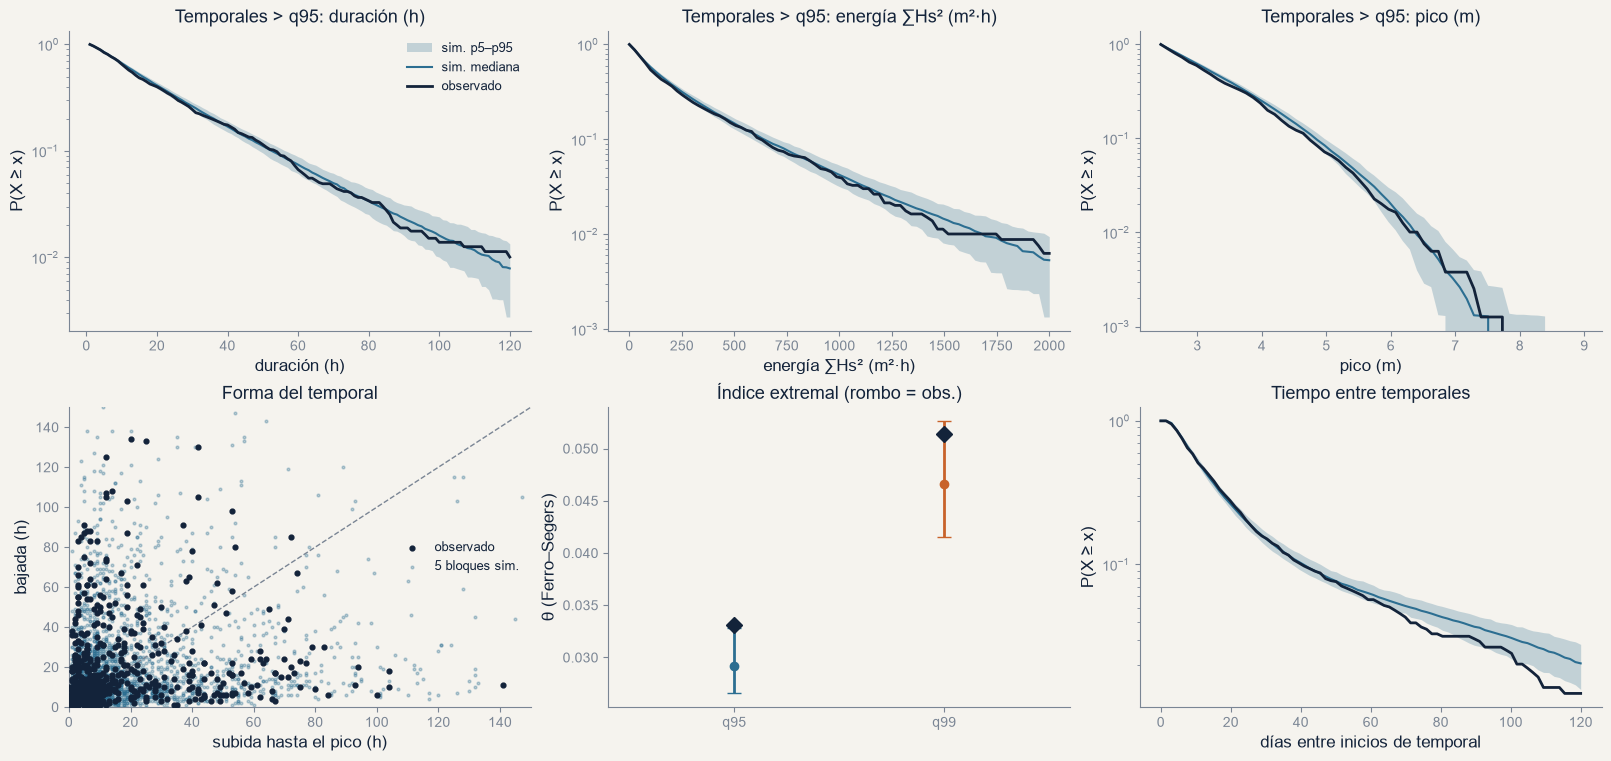

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
temporales > q95 / año,19.317,18.561,17.732,19.415,-3.914,True
dispersión nº/año (var/media),0.370,0.630,0.418,0.859,70.274,False
duración media (h),22.662,22.954,21.832,24.255,1.288,True
duración q90 (h),53.000,52.000,48.395,56.000,-1.887,True
energía media,246.827,257.701,240.624,273.417,4.406,True
subida / bajada (mediana),0.667,0.830,0.750,1.000,24.480,False
θ q95,0.033,0.029,0.027,0.033,-11.905,False
θ q99,0.051,0.047,0.041,0.053,-9.428,True
temporales > q99 / año,6.293,6.415,5.876,7.001,1.938,True


In [36]:
#### 5B. Temporales: duración, energía, forma, agrupamiento y cronología (umbral q95)
def figura_5b(est_list, nombre):
    """Figura y tabla de la sección 5B para una lista de estadísticos por bloque (emulador o hindcast)."""
    ev_o = est_obs["ev95"]
    ev_s = [e["ev95"] for e in est_list]
    superv = lambda x, grid: np.array([(x >= g).mean() for g in grid])

    fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), constrained_layout=True)
    for ax, col, tit, grid in [(axs[0, 0], "dur", "duración (h)", np.arange(1, 121)),
                               (axs[0, 1], "energia", "energía ∑Hs² (m²·h)", np.linspace(0, ev_o["energia"].quantile(.99) * 1.3, 80)),
                               (axs[0, 2], "pico", "pico (m)", np.linspace(U95, ev_o["pico"].max() * 1.15, 60))]:
        banda(ax, grid, np.array([superv(d[col].values, grid) for d in ev_s]))
        ax.semilogy(grid, superv(ev_o[col].values, grid), color=TINTA, lw=2, label="observado")
        ax.set(title=f"Temporales > q95: {tit}", xlabel=tit, ylabel="P(X ≥ x)")
    axs[0, 0].legend(frameon=False, fontsize=9)

    #### Forma: subida frente a bajada
    axs[1, 0].scatter(ev_o["subida"], ev_o["bajada"], s=12, color=TINTA, label="observado", zorder=3)
    d0 = pd.concat(ev_s[:5])
    axs[1, 0].scatter(d0["subida"], d0["bajada"], s=4, color=AZUL, alpha=0.3, label="5 bloques sim.")
    axs[1, 0].plot([0, 150], [0, 150], color=GRIS, ls="--", lw=1)
    axs[1, 0].set(xlim=(0, 150), ylim=(0, 150), xlabel="subida hasta el pico (h)", ylabel="bajada (h)", title="Forma del temporal")
    axs[1, 0].legend(frameon=False, fontsize=9)

    #### Índice extremal
    for j, (q, c) in enumerate([(95, AZUL), (99, NARANJA)]):
        v = np.array([e[f"theta_q{q}"] for e in est_list]); p5, p50, p95 = np.percentile(v, [5, 50, 95])
        axs[1, 1].errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=c, capsize=5, lw=2)
        axs[1, 1].plot(j, est_obs[f"theta_q{q}"], "D", color=TINTA, ms=8)
    axs[1, 1].set(xticks=[0, 1], xticklabels=["q95", "q99"], xlim=(-0.6, 1.6), ylabel="θ (Ferro–Segers)",
                  title="Índice extremal (rombo = obs.)")

    #### Tiempo entre temporales
    ia = lambda d: np.diff(d["inicio"].values) / 24
    grid = np.linspace(0, 120, 80)
    banda(axs[1, 2], grid, np.array([superv(ia(d), grid) for d in ev_s]))
    axs[1, 2].semilogy(grid, superv(ia(ev_o), grid), color=TINTA, lw=2)
    axs[1, 2].set(xlabel="días entre inicios de temporal", ylabel="P(X ≥ x)", title="Tiempo entre temporales")
    fig.savefig(f"figuras/val_temporales_{nombre}.png", dpi=200)
    plt.show()

    #### Tabla
    def fila_ev(nombre, f_obs, f_sim):
        s = np.array([f_sim(e) for e in est_list]); o = f_obs(est_obs)
        a, m, b = np.percentile(s, [5, 50, 95])
        return {"métrica": nombre, "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                "sesgo %": 100 * (m - o) / o if o else np.nan, "en banda": a <= o <= b}
    tabla_temp = pd.DataFrame([
        fila_ev("temporales > q95 / año",   lambda e: len(e["ev95"]) / N_ANOS, lambda e: len(e["ev95"]) / N_ANOS),
        fila_ev("dispersión nº/año (var/media)", lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean(),
                                                 lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean()),
        fila_ev("duración media (h)",        lambda e: e["ev95"]["dur"].mean(), lambda e: e["ev95"]["dur"].mean()),
        fila_ev("duración q90 (h)",          lambda e: e["ev95"]["dur"].quantile(.9), lambda e: e["ev95"]["dur"].quantile(.9)),
        fila_ev("energía media",             lambda e: e["ev95"]["energia"].mean(), lambda e: e["ev95"]["energia"].mean()),
        fila_ev("subida / bajada (mediana)", lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median(),
                                             lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median()),
        fila_ev("θ q95", lambda e: e["theta_q95"], lambda e: e["theta_q95"]),
        fila_ev("θ q99", lambda e: e["theta_q99"], lambda e: e["theta_q99"]),
        fila_ev("temporales > q99 / año",   lambda e: len(e["ev99"]) / N_ANOS, lambda e: len(e["ev99"]) / N_ANOS),
    ]).set_index("métrica")
    return tabla_temp

figura_5b(est_sim, GEN).round(3)


50 realizaciones del hindcast (05)


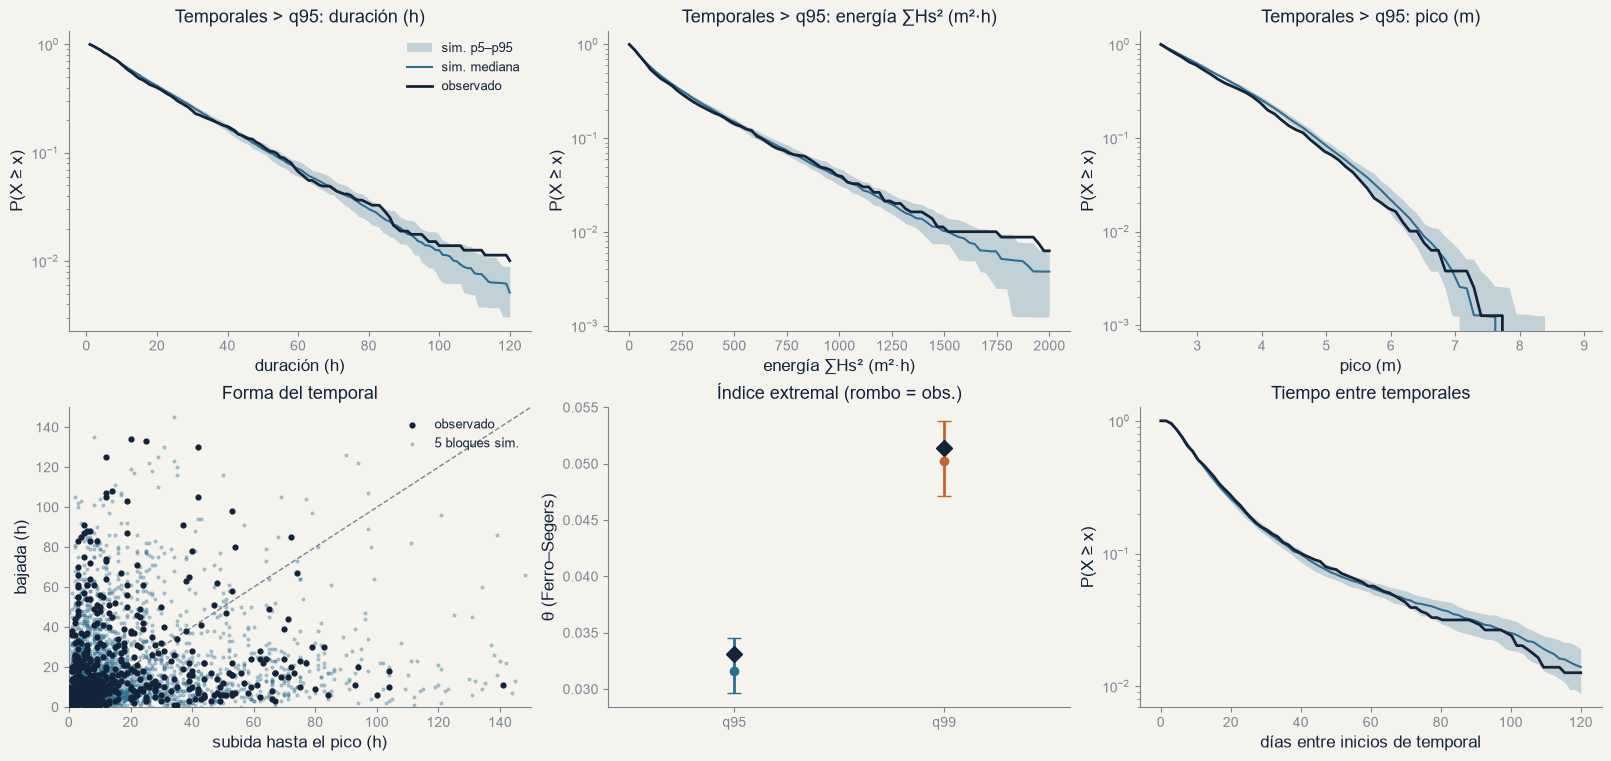

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
temporales > q95 / año,19.317,19.354,18.789,19.916,0.189,True
dispersión nº/año (var/media),0.370,0.640,0.485,0.775,72.965,False
duración media (h),22.662,22.661,21.972,23.378,-0.005,True
duración q90 (h),53.000,51.150,49.000,54.550,-3.491,True
energía media,246.827,251.396,243.588,259.159,1.851,True
subida / bajada (mediana),0.667,0.833,0.750,1.000,25.000,False
θ q95,0.033,0.032,0.030,0.035,-4.528,True
θ q99,0.051,0.050,0.047,0.054,-2.223,True
temporales > q99 / año,6.293,6.646,6.415,7.027,5.620,False


In [37]:
#### Misma validación con el hindcast del 05 (f histórica + ruido, sin PVAR): ¿qué parte es del generador?
obj = pd.read_pickle(f"outputs/ruido/hs_hindcast_{point}.pkl")              # DataFrame: una columna por realización
if isinstance(obj, dict):
    obj = obj.get("hs_sims", next(iter(obj.values())))
if isinstance(obj, pd.DataFrame):
    series_07 = [obj[c] for c in obj.columns]
else:
    series_07 = list(obj)

est_07 = []
for s in series_07:
    s = s.astype("float64").loc["1985":"2025"]
    s = s[s.index.year.isin(np.unique(obs.index.year))]       # mismos años que la observación
    est_07.append(estadisticos(s))
print(f"{len(est_07)} realizaciones del hindcast (05)")

est_sim_08 = est_sim                                          # alias para las celdas siguientes (emulador)
figura_5b(est_07, "hindcast").round(3)


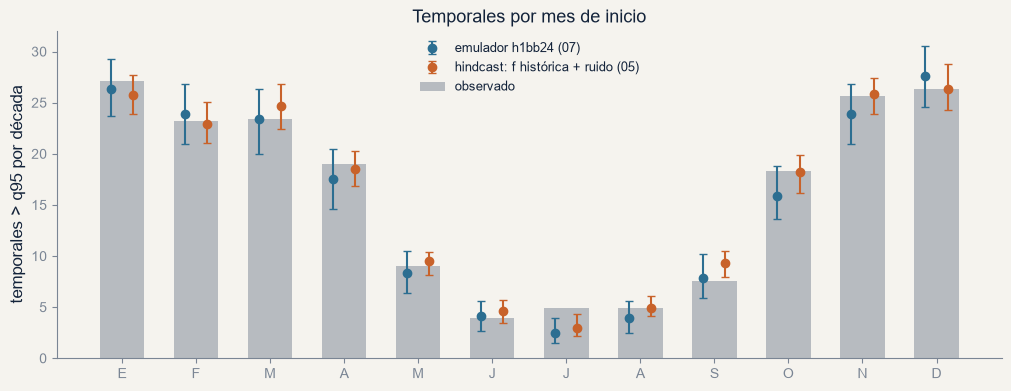

                       1     2     3     4    5    6    7    8    9     10  \
obs                  27.1  23.2  23.4  19.0  9.0  3.9  4.9  4.9  7.6  18.3   
emulador h1bb24 p50  26.3  23.9  23.4  17.6  8.3  4.1  2.4  3.9  7.8  15.9   
hindcast p50         25.7  22.9  24.6  18.5  9.5  4.6  2.9  4.9  9.3  18.2   

                       11    12  
obs                  25.6  26.3  
emulador h1bb24 p50  23.9  27.6  
hindcast p50         25.9  26.3  


In [38]:
#### Temporales > q95 por mes (por década): ¿faltan en primavera/otoño?
def por_mes(e, s_index):
    """Nº de temporales > q95 por mes de inicio, por década."""
    ini = e["ev95"]["inicio"].astype(int).values
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[ini].month, minlength=13)[1:] * 10 / n_anos

mo = por_mes(est_obs, obs.asfreq("h").index)
#### índices horarios de cada bloque / simulación para traducir 'inicio' a fecha
def indices_08():
    out = []
    for fic in ficheros:
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"]
        anos = np.unique(hs.index.year); anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]
        for b in range(len(anos) // N_ANOS):
            out.append(hs[hs.index.year.isin(anos[b * N_ANOS:(b + 1) * N_ANOS])].asfreq("h").index)
    return out
idx_08 = indices_08()
m08 = np.array([por_mes(e, ix) for e, ix in zip(est_sim_08, idx_08)])
m07 = np.array([por_mes(e, s.loc["1985":"2025"].asfreq("h").index) for e, s in zip(est_07, series_07)])

meses = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
for arr_, c, lab, dx in [(m08, AZUL, f"emulador {GEN} (07)", -0.15), (m07, NARANJA, "hindcast: f histórica + ruido (05)", 0.15)]:
    p5, p50, p95 = np.percentile(arr_, [5, 50, 95], axis=0)
    ax.errorbar(meses + dx, p50, yerr=[p50 - p5, p95 - p50], fmt="o", color=c, capsize=3, lw=1.5, label=lab)
ax.bar(meses, mo, width=0.6, color=GRIS, alpha=0.5, label="observado")
ax.set(xticks=meses, xticklabels=["E","F","M","A","M","J","J","A","S","O","N","D"],
       ylabel="temporales > q95 por década", title="Temporales por mes de inicio")
ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/val_temporales_mes_{GEN}.png", dpi=200)
plt.show()

print(pd.DataFrame({"obs": mo, f"emulador {GEN} p50": np.median(m08, 0), "hindcast p50": np.median(m07, 0)},
                   index=meses).round(1).T)

In [39]:
#### ¿Faltan horas por encima de q95 o faltan episodios? (por mes, por década)
def horas_mes(s_values, s_index, u):
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[s_values > u].month, minlength=13)[1:] * 10 / n_anos

obs_h = obs.asfreq("h")
h_obs = horas_mes(obs_h.values, obs_h.index, U95)
h_07 = np.array([horas_mes(s.loc["1985":"2025"].values, s.loc["1985":"2025"].index, U95) for s in series_07])

tabla = pd.DataFrame({
    "horas obs": h_obs, "horas hindcast": np.median(h_07, 0),
    "episodios obs": mo, "episodios hindcast": np.median(m07, 0)}, index=meses)
tabla["h/episodio obs"] = tabla["horas obs"] / tabla["episodios obs"]
tabla["h/episodio hindcast"] = tabla["horas hindcast"] / tabla["episodios hindcast"]
tabla.round(1).T

,1,2,3,4,5,6,7,8,9,10,11,12
horas obs,766.3,618.0,622.7,301.2,112.2,43.4,29.0,32.7,106.1,335.9,682.9,727.1
horas hindcast,725.1,605.5,616.2,324.6,123.3,38.7,21.8,43.4,106.3,346.1,682.3,736.0
episodios obs,27.1,23.2,23.4,19.0,9.0,3.9,4.9,4.9,7.6,18.3,25.6,26.3
episodios hindcast,25.7,22.9,24.6,18.5,9.5,4.6,2.9,4.9,9.3,18.2,25.9,26.3
h/episodio obs,28.3,26.7,26.6,15.8,12.4,11.1,6.0,6.7,14.0,18.4,26.7,27.6
h/episodio hindcast,28.2,26.4,25.0,17.5,13.0,8.3,7.5,8.9,11.5,19.0,26.4,27.9
